# **Data Exploration**

## Setup and Data Loading

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown
from io import StringIO
import py7zr
import os, sys, subprocess

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
warnings.filterwarnings("ignore")


In [3]:
RAW_ARCHIVE = Path(
    r"..\data\raw\REFIT_RAW_081116.7z"
)

DATA_PATH = Path(r"..\data\raw")

In [4]:
import re
import py7zr
from pathlib import Path

def extract_house_csv(archive_path, house_no, output_dir=None):
    archive_path = Path(archive_path)

    if not archive_path.is_file():
        raise FileNotFoundError(f"Archive not found: {archive_path}")

    output_dir = Path(output_dir) if output_dir else archive_path.parent

    # Match House1, House_1, House-1, but not House10
    pattern = re.compile(
        rf"house[_\s-]?0*{int(house_no)}(?!\d)",
        re.IGNORECASE
    )

    with py7zr.SevenZipFile(archive_path, mode="r") as archive:
        matching_files = [
            name for name in archive.getnames()
            if Path(name).suffix.lower() == ".csv"
            and pattern.search(Path(name).stem)
        ]

        if not matching_files:
            print(f"House {house_no}: No matching CSV files found.")
            return []

        existing_files = []
        missing_files = []

        for name in matching_files:
            target_path = output_dir / name

            if target_path.is_file() and target_path.stat().st_size > 0:
                existing_files.append(name)
                print(f"Skipped (already exists): {name}")
            else:
                missing_files.append(name)

        if missing_files:
            output_dir.mkdir(parents=True, exist_ok=True)

            archive.extract(
                path=output_dir,
                targets=missing_files
            )

            for name in missing_files:
                print(f"Extracted: {name}")
        else:
            print(f"All House {house_no} files already exist. Nothing to extract.")

    print(
        f"\nHouse {house_no} Summary: "
        f"{len(missing_files)} extracted, "
        f"{len(existing_files)} skipped."
    )

    return [output_dir / name for name in matching_files]

In [5]:
house_no = 1

extracted_files = extract_house_csv(
    archive_path=RAW_ARCHIVE,
    house_no=house_no,
    output_dir=RAW_ARCHIVE.parent
)

Skipped (already exists): RAW_House1_Part1.csv
Skipped (already exists): RAW_House1_Part2.csv
All House 1 files already exist. Nothing to extract.

House 1 Summary: 0 extracted, 2 skipped.


In [6]:
raw_files = sorted(DATA_PATH.rglob("*.csv"))
print(raw_files)

[WindowsPath('../data/raw/RAW_House1_Part1.csv'), WindowsPath('../data/raw/RAW_House1_Part2.csv')]


In [7]:
def load_data(file_path):
    df = pd.read_csv(file_path)
    return df

raw_df1 = load_data(raw_files[0]) #Part1
raw_df2 = load_data(raw_files[1]) #Part2

In [8]:
def data_stats(df: pd.DataFrame, sample_rows: int = 5) -> None:

    def section(title):
        display(Markdown(f"### {title}"))

    # 1. Dataset Overview
    section("Dataset Overview")

    overview = pd.DataFrame({
        "Metric": ["Rows", "Columns", "Duplicates"],
        "Value": [
            f"{df.shape[0]:,}",
            df.shape[1],
            f"{df.duplicated().sum():,}"
        ]
    })
    display(overview.set_index("Metric"))

    # 2. Sample Data
    section("Sample Data")
    display(df.head(sample_rows))

    # 3. Column Information
    section("Column Information")

    column_info = pd.DataFrame({
        "Data Type": df.dtypes.astype(str),
        "Non-Null Count": df.notna().sum(),
        "Missing Count": df.isna().sum(),
        "Missing (%)": (df.isna().mean() * 100).round(2),
        "Unique Values": df.nunique(dropna=True)
    })

    display(
        column_info.style
        .background_gradient(subset=["Missing (%)"], cmap="Reds")
        .format({"Missing (%)": "{:.2f}%"})
    )

    # 4. DataFrame Info
    section("DataFrame Info")

    buffer = StringIO()
    df.info(buf=buffer, memory_usage="deep")
    print(buffer.getvalue())

    # 5. Descriptive Statistics
    section("Descriptive Statistics")

    display(df.describe(include="all").T)

    # 6. Missing Values Summary
    section("Missing Values")

    missing = pd.DataFrame({
        "Missing Count": df.isna().sum(),
        "Missing (%)": df.isna().mean() * 100
    })

    missing = missing[missing["Missing Count"] > 0]
    missing = missing.sort_values("Missing Count", ascending=False)

    if missing.empty:
        display(Markdown("**No missing values found.**"))
    else:
        display(
            missing.style
            .background_gradient(subset=["Missing (%)"], cmap="Reds")
            .format({"Missing (%)": "{:.2f}%"})
        )

In [9]:
data_stats(raw_df1)

### Dataset Overview

,Value
Metric,
Rows,"4,377,877"
Columns,12
Duplicates,"595,935"


### Sample Data

,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
0,2013-10-09 14:06:17,1381327577,523,74,0,69,0,0,0,0,0,1
1,2013-10-09 14:06:31,1381327591,526,75,0,69,0,0,0,0,0,1
2,2013-10-09 14:06:46,1381327606,540,74,0,68,0,0,0,0,0,1
3,2013-10-09 14:07:01,1381327621,532,74,0,68,0,0,0,0,0,1
4,2013-10-09 14:07:15,1381327634,540,74,0,69,0,0,0,0,0,1


### Column Information

...

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4377877 entries, 0 to 4377876
Data columns (total 12 columns):
 #   Column      Dtype 
---  ------      ----- 
 0   Time        object
 1   Unix        int64 
 2   Aggregate   int64 
 3   Appliance1  int64 
 4   Appliance2  int64 
 5   Appliance3  int64 
 6   Appliance4  int64 
 7   Appliance5  int64 
 8   Appliance6  int64 
 9   Appliance7  int64 
 10  Appliance8  int64 
 11  Appliance9  int64 
dtypes: int64(11), object(1)
memory usage: 651.3 MB



### Descriptive Statistics

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Time,4377877,3732363,2014-05-29 01:15:56,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Unix,4377877.0,NaN,NaN,NaN,1397106296.711559,9204911.385599,1381327577.0,1388065938.0,1398298115.0,1404914391.0,1412126827.0
Aggregate,4377877.0,NaN,NaN,NaN,484.646877,788.135072,0.0,184.0,240.0,491.0,24000.0
Appliance1,4377877.0,NaN,NaN,NaN,19.599035,178.876153,0.0,0.0,0.0,0.0,69629.0
Appliance2,4377877.0,NaN,NaN,NaN,17.503916,103.323512,0.0,0.0,0.0,45.0,98301.0
Appliance3,4377877.0,NaN,NaN,NaN,29.156209,53.196832,0.0,0.0,0.0,70.0,32751.0
Appliance4,4377877.0,NaN,NaN,NaN,8.186992,521.701229,0.0,0.0,0.0,0.0,98301.0
Appliance5,4377877.0,NaN,NaN,NaN,9.695591,137.936251,0.0,0.0,0.0,0.0,32767.0
Appliance6,4377877.0,NaN,NaN,NaN,10.851777,155.98616,0.0,0.0,0.0,0.0,14336.0
Appliance7,4377877.0,NaN,NaN,NaN,1.930247,81.684846,0.0,0.0,0.0,0.0,98299.0


### Missing Values

**No missing values found.**

In [10]:
data_stats(raw_df2)

### Dataset Overview

,Value
Metric,
Rows,"4,140,886"
Columns,12
Duplicates,0


### Sample Data

,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
0,2014-06-27 21:57:50,1403906269,322.0,0.0,0.0,72.0,0.0,0.0,0.0,0.0,NaN,NaN
1,2014-06-27 21:57:51,1403906271,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,1.0
2,2014-06-27 21:57:58,1403906278,329.0,NaN,0.0,NaN,NaN,0.0,0.0,0.0,30.0,NaN
3,2014-06-27 21:58:06,1403906286,322.0,0.0,0.0,71.0,NaN,NaN,NaN,0.0,30.0,NaN
4,2014-06-27 21:58:14,1403906293,320.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,30.0,NaN


### Column Information

...

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4140886 entries, 0 to 4140885
Data columns (total 12 columns):
 #   Column      Dtype  
---  ------      -----  
 0   Time        object 
 1   Unix        int64  
 2   Aggregate   float64
 3   Appliance1  float64
 4   Appliance2  float64
 5   Appliance3  float64
 6   Appliance4  float64
 7   Appliance5  float64
 8   Appliance6  float64
 9   Appliance7  float64
 10  Appliance8  float64
 11  Appliance9  float64
dtypes: float64(10), int64(1), object(1)
memory usage: 616.1 MB



### Descriptive Statistics

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Time,4140886,4140886,2015-07-10 11:56:32,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Unix,4140886.0,NaN,NaN,NaN,1420168346.859313,9082612.413175,1403906269.0,1412850679.0,1420171447.5,1427443799.25,1436529392.0
Aggregate,3951913.0,NaN,NaN,NaN,446.46093,813.971674,15.0,185.0,234.0,363.0,29159.0
Appliance1,3702996.0,NaN,NaN,NaN,18.836473,174.084717,0.0,0.0,0.0,0.0,76677.0
Appliance2,3681418.0,NaN,NaN,NaN,16.866454,79.201702,0.0,0.0,0.0,46.0,66685.0
Appliance3,3828925.0,NaN,NaN,NaN,30.140084,96.393188,0.0,0.0,0.0,70.0,73725.0
Appliance4,3629923.0,NaN,NaN,NaN,1.727778,155.512219,0.0,0.0,0.0,0.0,98301.0
Appliance5,3643663.0,NaN,NaN,NaN,12.189151,180.002162,0.0,0.0,0.0,0.0,73725.0
Appliance6,3798549.0,NaN,NaN,NaN,11.327544,160.340753,0.0,0.0,0.0,0.0,37610.0
Appliance7,3908134.0,NaN,NaN,NaN,3.969312,178.34074,0.0,0.0,0.0,0.0,73725.0


### Missing Values

,Missing Count,Missing (%)
Appliance9,1911811,46.17%
Appliance4,510963,12.34%
Appliance5,497223,12.01%
Appliance2,459468,11.10%
Appliance1,437890,10.57%
Appliance8,390705,9.44%
Appliance6,342337,8.27%
Appliance3,311961,7.53%
Appliance7,232752,5.62%
Aggregate,188973,4.56%


In [16]:
def clean_data(df):
    df = df.copy()

    # 1. Timestamp conversion
    if 'Time' not in df.columns:
        raise KeyError("Missing 'Time' column")

    df['Time'] = pd.to_datetime(
        df['Time'], errors='coerce'
    )

    invalid_count = df['Time'].isna().sum()
    print(f"Invalid timestamps: {invalid_count}")

    df = df.dropna(subset=['Time'])

    # 2. Sort chronologically (stable sorting)
    df = df.sort_values('Time', kind='stable')

    # 3. Duplicate diagnostics
    exact_duplicates = df.duplicated().sum()
    timestamp_duplicates = df.duplicated(subset=['Time']).sum()

    print(f"Exact duplicate records: {exact_duplicates}")
    print(f"Duplicate timestamp rows: {timestamp_duplicates}")

    # 4. Select columns
    appliance_cols = [
        col for col in df.columns
        if col.lower().startswith('appliance')
    ]

    numeric_cols = ['Unix', 'Aggregate'] + appliance_cols

    # Convert numerical columns once
    df[numeric_cols] = df[numeric_cols].apply(
        pd.to_numeric, errors='coerce'
    )

    df[numeric_cols] = df[numeric_cols].mask(
        df[numeric_cols].eq(0)
    )

    # 6. Pandas aggregation
    agg_rules = {
        'Unix': 'last',
        'Aggregate': 'max',
        **{col: 'max' for col in appliance_cols}
    }

    df = (
        df.groupby('Time', sort=True, as_index=False)
          .agg(agg_rules)
    )

    # 7. Replace missing aggregated values with zero
    df[numeric_cols] = df[numeric_cols].fillna(0)

    print(
        f"Remaining duplicates: "
        f"{df['Time'].duplicated().sum()}"
    )
    print(f"Final shape: {df.shape}")

    return df


In [24]:
print("******Cleaning raw_df1******")
cleaned_df1 = clean_data(raw_df1)
print("******Cleaning raw_df2******")
cleaned_df2 = clean_data(raw_df2)
combined_raw_df = pd.concat([cleaned_df1, cleaned_df2], ignore_index=True)
print("******Cleaning combined_raw_df******")
combined_cleaned_df = clean_data(combined_raw_df)

******Cleaning raw_df1******
Invalid timestamps: 0
Exact duplicate records: 595935
Duplicate timestamp rows: 645514
Remaining duplicates: 0
Final shape: (3732363, 12)
******Cleaning raw_df2******
Invalid timestamps: 0
Exact duplicate records: 0
Duplicate timestamp rows: 0
Remaining duplicates: 0
Final shape: (4140886, 12)
******Cleaning combined_raw_df******
Invalid timestamps: 0
Exact duplicate records: 5
Duplicate timestamp rows: 116037
Remaining duplicates: 0
Final shape: (7757212, 12)


In [25]:
data_stats(combined_cleaned_df)

### Dataset Overview

,Value
Metric,
Rows,"7,757,212"
Columns,12
Duplicates,0


### Sample Data

,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
0,2013-10-09 14:06:17,1381327577,523.0,74.0,0.0,69.0,0.0,0.0,0.0,0.0,0.0,1.0
1,2013-10-09 14:06:31,1381327591,526.0,75.0,0.0,69.0,0.0,0.0,0.0,0.0,0.0,1.0
2,2013-10-09 14:06:46,1381327606,540.0,74.0,0.0,68.0,0.0,0.0,0.0,0.0,0.0,1.0
3,2013-10-09 14:07:01,1381327621,532.0,74.0,0.0,68.0,0.0,0.0,0.0,0.0,0.0,1.0
4,2013-10-09 14:07:15,1381327634,540.0,74.0,0.0,69.0,0.0,0.0,0.0,0.0,0.0,1.0


### Column Information

...

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7757212 entries, 0 to 7757211
Data columns (total 12 columns):
 #   Column      Dtype         
---  ------      -----         
 0   Time        datetime64[ns]
 1   Unix        int64         
 2   Aggregate   float64       
 3   Appliance1  float64       
 4   Appliance2  float64       
 5   Appliance3  float64       
 6   Appliance4  float64       
 7   Appliance5  float64       
 8   Appliance6  float64       
 9   Appliance7  float64       
 10  Appliance8  float64       
 11  Appliance9  float64       
dtypes: datetime64[ns](1), float64(10), int64(1)
memory usage: 710.2 MB



### Descriptive Statistics

,count,mean,min,25%,50%,75%,max,std
Time,7757212,2014-08-26 01:07:52.224713216,2013-10-09 14:06:17,2014-04-20 20:00:20.750000128,2014-08-23 09:21:32.500000,2015-01-12 10:00:42.500000,2015-07-10 11:56:32,NaN
Unix,7757212.0,1409015271.737334,1381327577.0,1398024020.5,1408785692.0,1421056841.75,1436529392.0,14989526.072268
Aggregate,7757212.0,458.145969,0.0,183.0,234.0,402.0,29159.0,797.079642
Appliance1,7757212.0,18.134855,0.0,0.0,0.0,0.0,76677.0,175.88239
Appliance2,7757212.0,16.112981,0.0,0.0,0.0,45.0,98301.0,87.70326
Appliance3,7757212.0,28.427658,0.0,0.0,0.0,70.0,73725.0,77.066438
Appliance4,7757212.0,4.504946,0.0,0.0,0.0,0.0,98301.0,357.247035
Appliance5,7757212.0,10.381005,0.0,0.0,0.0,0.0,73725.0,156.050531
Appliance6,7757212.0,10.600034,0.0,0.0,0.0,0.0,37610.0,154.727274
Appliance7,7757212.0,2.890214,0.0,0.0,0.0,0.0,98299.0,140.660291


### Missing Values

**No missing values found.**

## Missing Readings and Irregular Intervals
Resample to 1-minute intervals. Fill short gaps and flag long outages.

In [28]:
# Set time as index for resampling
df_time_indexed = combined_cleaned_df.set_index('Time')

# Resample to 1-minute intervals
print("Resampling data to 1-minute intervals...")
# For aggregate power and appliance power, mean is generally used for downsampling
# Since readings were originally ~8 seconds, we use mean()
df_resampled = df_time_indexed.resample('1T').mean()

# Count missing values after resampling
missing_vals = df_resampled.isnull().sum().max()
print(f"Missing 1-minute intervals: {missing_vals}")

# Handle short gaps (e.g., up to 5 minutes) by forward filling
df_resampled = df_resampled.ffill(limit=5)

# Flag long outages (remaining NaNs after ffill)
outage_mask = df_resampled.isnull().any(axis=1)
print(f"Number of intervals flagged as long outages: {outage_mask.sum()}")

# For modelling, we can fill long outages with 0 or leave as NaN to mask out during training.
# We will leave as NaN to signify flagged outages.
df_cleaned = df_resampled

Resampling data to 1-minute intervals...
Missing 1-minute intervals: 115078
Number of intervals flagged as long outages: 112374


## Impossible or Extreme Values

In [29]:
numeric_cols = df_cleaned.select_dtypes(include=[np.number]).columns

for col in numeric_cols:
    min_val = df_cleaned[col].min()
    max_val = df_cleaned[col].max()
    print(f"{col} - Min: {min_val:.2f}, Max: {max_val:.2f}")
    
    # Clip negative values to 0
    df_cleaned[col] = df_cleaned[col].clip(lower=0)

Unix - Min: 1381327591.33, Max: 1436529377.60
Aggregate - Min: 0.00, Max: 23578.00
Appliance1 - Min: 0.00, Max: 32770.50
Appliance2 - Min: 0.00, Max: 28086.00
Appliance3 - Min: 0.00, Max: 10922.67
Appliance4 - Min: 0.00, Max: 98301.00
Appliance5 - Min: 0.00, Max: 16387.25
Appliance6 - Min: 0.00, Max: 5734.40
Appliance7 - Min: 0.00, Max: 73725.00
Appliance8 - Min: 0.00, Max: 39339.00
Appliance9 - Min: 0.00, Max: 16384.50


## Plotting Power Channels

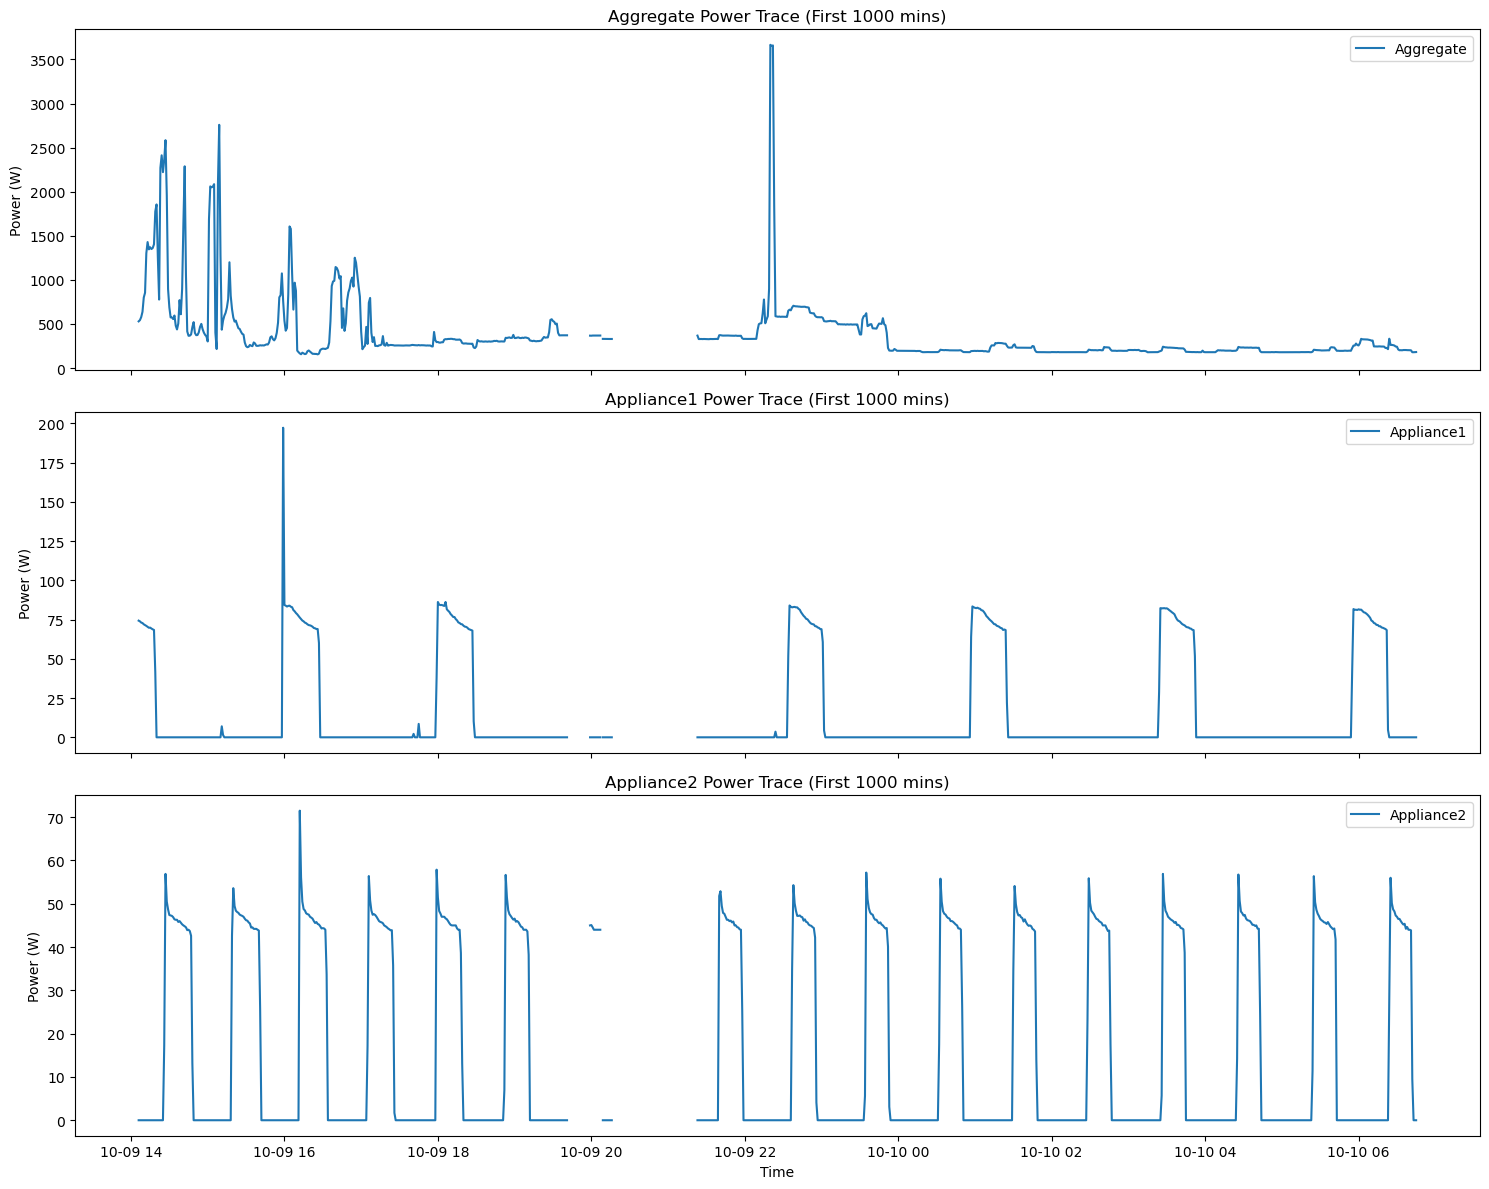

In [30]:
plot_cols = [c for c in df_cleaned.columns if c in ['Aggregate', 'Appliance1', 'Appliance2', 'Appliance3']][:3]

if plot_cols:
    fig, axes = plt.subplots(nrows=len(plot_cols), ncols=1, figsize=(15, 4 * len(plot_cols)), sharex=True)
    if len(plot_cols) == 1: axes = [axes]
    
    for ax, col in zip(axes, plot_cols):
        ax.plot(df_cleaned.index[:1000], df_cleaned[col].iloc[:1000], label=col)
        ax.set_ylabel('Power (W)')
        ax.legend(loc='upper right')
        ax.set_title(f"{col} Power Trace (First 1000 mins)")
    
    plt.xlabel('Time')
    plt.tight_layout()
    plt.show()
else:
    print("Could not find exact columns for Aggregate/Appliance to plot, please adjust column names.")

In [ ]:
##run to save it
# df_cleaned.to_csv(DATA_PATH/'cleaned_refit_data.csv', index=True)